# Notebook 05 — Machine Learning
## Drug–Target Binding Affinity Prediction

This notebook develops and evaluates machine-learning models for predicting
drug–target binding affinity (`pChEMBL`) using molecular fingerprints and
protein sequence-derived features.

### Main workflow

1. Load and validate the integrated dataset
2. Explore binding-affinity distributions
3. Establish a baseline Random Forest model
4. Evaluate random, drug-grouped, and protein-grouped performance
5. Integrate Morgan molecular fingerprints
6. Integrate enhanced protein features and 400 dipeptide features
7. Train the enhanced model
8. Analyse predictions, residuals, and feature importance
9. Compare baseline and enhanced models
10. Save all final ML results

## 1. Import Libraries

The required libraries for data handling, visualization, machine learning,
model evaluation, and cross-validation are imported.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit,
    GroupKFold
)

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.base import clone

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load Integrated Dataset

The integrated dataset contains experimentally measured drug–target
binding affinity together with the previously generated molecular and
protein features.

In [2]:
ml_df = pd.read_csv(
    "../data/processed/ml_feature_dataset.csv"
)

print("Dataset shape:", ml_df.shape)
print(
    "Missing values:",
    ml_df.isna().sum().sum()
)

Dataset shape: (125, 42)
Missing values: 0


## 3. Inspect Dataset

The first observations, columns, data types, and basic structure are
inspected before modelling.

In [3]:
print(ml_df.head())

print("\nNumber of columns:", len(ml_df.columns))

print("\nData types:")
print(ml_df.dtypes)

  molecule_chembl_id target_chembl_id  pchembl_value  n_measurements  \
0           CHEMBL10       CHEMBL1862          5.495               2   
1           CHEMBL10        CHEMBL203          5.770              23   
2         CHEMBL1000        CHEMBL231          7.500              11   
3       CHEMBL100075        CHEMBL205          8.150               1   
4       CHEMBL100109        CHEMBL204          9.620               1   

  activity_types                       pref_name_x      organism  \
0             Kd      Tyrosine-protein kinase ABL1  Homo sapiens   
1             Kd  Epidermal growth factor receptor  Homo sapiens   
2             Ki             Histamine H1 receptor  Homo sapiens   
3             Ki              Carbonic anhydrase 2  Homo sapiens   
4             Ki                       Prothrombin  Homo sapiens   

                                    canonical_smiles  mol_weight    logp  ...  \
0  C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...     377.444  4.6822  ...

## 4. Define Target Variable

The pChEMBL value is used as the continuous regression target.
Higher pChEMBL values correspond to stronger measured binding affinity.

In [4]:
y = ml_df["pchembl_value"]

print("Target shape:", y.shape)
print(y.describe())

Target shape: (125,)
count    125.000000
mean       7.389760
std        1.513624
min        3.965000
25%        6.520000
50%        7.680000
75%        8.300000
max       10.480000
Name: pchembl_value, dtype: float64


## 5. Visualize pChEMBL Distribution

The distribution of experimentally measured pChEMBL values is visualized
to understand the target range and identify potential skew or extreme values.

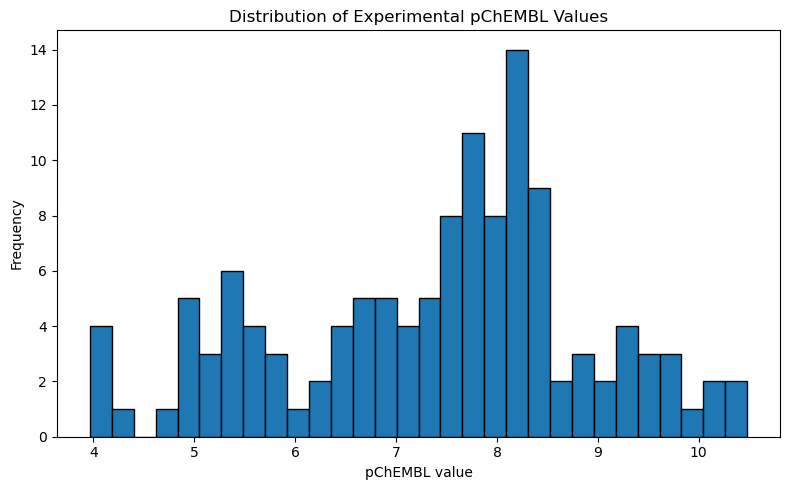

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(
    y,
    bins=30,
    edgecolor="black"
)

plt.xlabel("pChEMBL value")
plt.ylabel("Frequency")
plt.title("Distribution of Experimental pChEMBL Values")

plt.tight_layout()
plt.show()

## 6. Binding Affinity by Measurement Type

The cleaned dataset contains multiple binding-affinity measurement types.
Their frequency is visualized to understand the experimental composition
of the dataset.

In [6]:
if "standard_type" in ml_df.columns:
    type_counts = (
        ml_df["standard_type"]
        .value_counts()
        .head(10)
    )

    plt.figure(figsize=(9, 5))
    type_counts.plot(kind="bar")
    plt.xlabel("Standard measurement type")
    plt.ylabel("Number of records")
    plt.title("Binding-Affinity Records by Measurement Type")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("standard_type is not available in the integrated dataset.")

standard_type is not available in the integrated dataset.


## 7. Construct Baseline Feature Matrix

Identifier, metadata, and target columns are excluded from the predictor
matrix. Only numerical features are retained.

In [7]:
exclude_columns = [
    "molecule_chembl_id",
    "target_chembl_id",
    "pref_name",
    "pref_name_x",
    "pref_name_y",
    "organism",
    "canonical_smiles",
    "activity_types",
    "uniprot_accession",
    "n_measurements",
    "pchembl_value"
]

feature_columns = [
    col
    for col in ml_df.columns
    if col not in exclude_columns
]

X = ml_df[feature_columns]

print("X shape:", X.shape)
print("y shape:", y.shape)
print(
    "Non-numeric features:",
    X.select_dtypes(exclude=np.number).columns.tolist()
)

X shape: (125, 32)
y shape: (125,)
Non-numeric features: []


## 8. Feature Correlation with Binding Affinity

Pearson correlation is used as an exploratory measure of the linear
relationship between individual numerical features and pChEMBL.

In [8]:
numeric_df = ml_df.select_dtypes(
    include=np.number
)

correlations = (
    numeric_df.corr()["pchembl_value"]
    .drop("pchembl_value")
    .sort_values(
        key=lambda s: s.abs(),
        ascending=False
    )
)

print(correlations.head(20))

charged_fraction    0.569319
G_freq              0.456315
D_freq              0.445227
hba                 0.403415
M_freq             -0.402662
mol_weight          0.391806
S_freq             -0.376244
Q_freq              0.356680
A_freq              0.335490
Y_freq             -0.329858
rotatable_bonds     0.327942
T_freq             -0.327222
I_freq             -0.300610
tpsa                0.290968
E_freq              0.287037
N_freq             -0.277155
logp               -0.273927
sequence_length    -0.221023
P_freq             -0.162486
C_freq             -0.150577
Name: pchembl_value, dtype: float64


## 9. Visualize Top Feature Correlations

The strongest absolute correlations with pChEMBL are visualized.
Correlation does not imply causation; this plot is used for exploratory
feature analysis.

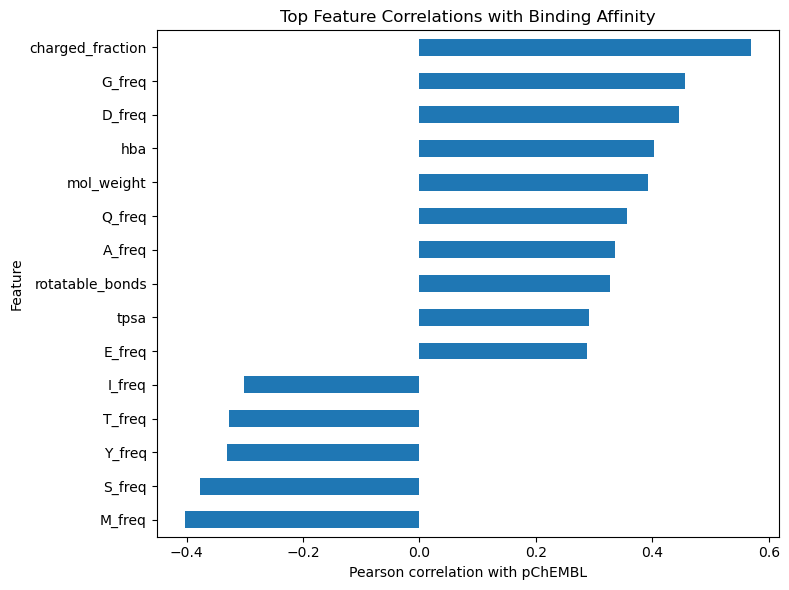

In [9]:
top_corr = correlations.head(15).sort_values()

plt.figure(figsize=(8, 6))
top_corr.plot(kind="barh")

plt.xlabel("Pearson correlation with pChEMBL")
plt.ylabel("Feature")
plt.title("Top Feature Correlations with Binding Affinity")

plt.tight_layout()
plt.show()

## 10. Random Train/Test Split

An 80:20 random split provides the initial baseline evaluation.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (100, 32)
Test set: (25, 32)


## 11. Train Baseline Random Forest

A Random Forest regression model is trained as the baseline machine-
learning model.

In [11]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    max_features="sqrt"
)

rf_model.fit(
    X_train,
    y_train
)

print(
    "Baseline Random Forest training completed."
)

Baseline Random Forest training completed.


## 12. Evaluate Baseline Model

The baseline model is evaluated using MAE, RMSE, and R².

In [12]:
y_pred = rf_model.predict(
    X_test
)

baseline_mae = mean_absolute_error(
    y_test,
    y_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

baseline_r2 = r2_score(
    y_test,
    y_pred
)

print(
    f"MAE  : {baseline_mae:.4f}"
)

print(
    f"RMSE : {baseline_rmse:.4f}"
)

print(
    f"R²   : {baseline_r2:.4f}"
)

MAE  : 0.5484
RMSE : 0.7765
R²   : 0.6293


## 13. Actual vs Predicted — Baseline

The relationship between experimental and predicted binding affinity is
visualized. Points close to the diagonal represent more accurate predictions.

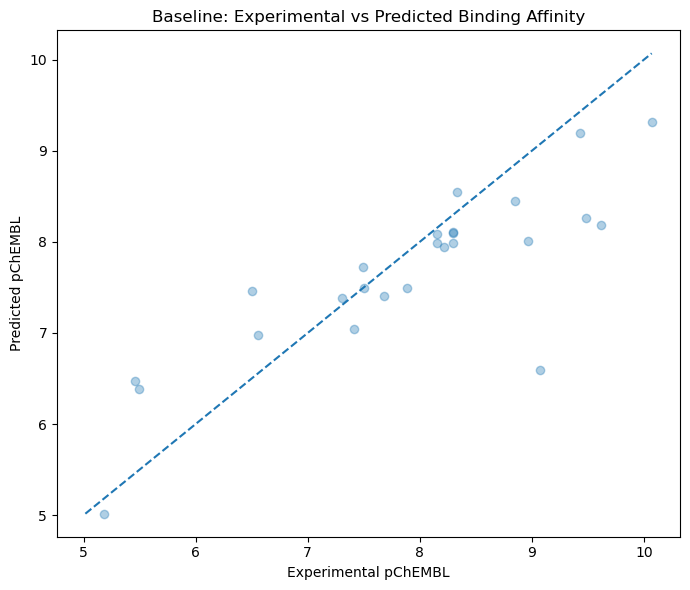

In [13]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.35
)

line_min = min(
    y_test.min(),
    y_pred.min()
)

line_max = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [line_min, line_max],
    [line_min, line_max],
    linestyle="--"
)

plt.xlabel("Experimental pChEMBL")
plt.ylabel("Predicted pChEMBL")
plt.title("Baseline: Experimental vs Predicted Binding Affinity")

plt.tight_layout()
plt.show()

## 14. Baseline Residual Analysis

Residuals are calculated as experimental minus predicted pChEMBL.
The residual distribution is inspected to identify systematic prediction
errors.

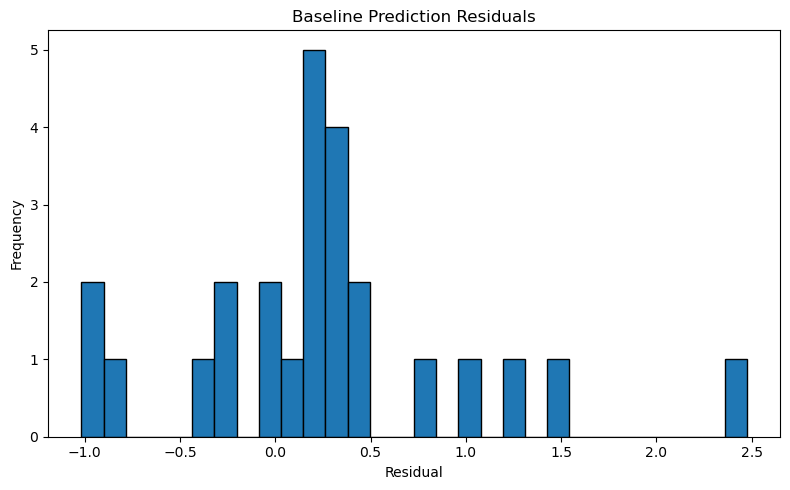

In [14]:
baseline_residuals = (
    y_test - y_pred
)

plt.figure(figsize=(8, 5))

plt.hist(
    baseline_residuals,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Baseline Prediction Residuals")

plt.tight_layout()
plt.show()

## 15. Baseline Feature Importance

Random Forest feature importance identifies features that contribute most
to the baseline prediction.

In [15]:
baseline_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print(
    baseline_importance.head(20)
)

                 feature  importance
0             mol_weight    0.097782
28                Y_freq    0.092289
5        rotatable_bonds    0.089678
1                   logp    0.085726
2                   tpsa    0.079475
11                D_freq    0.066013
22                Q_freq    0.062982
4                    hba    0.060136
14                G_freq    0.058136
7          fraction_csp3    0.054416
30      charged_fraction    0.041347
3                    hbd    0.036193
6             ring_count    0.021958
13                F_freq    0.016813
16                I_freq    0.012529
12                E_freq    0.012413
21                P_freq    0.010804
29  hydrophobic_fraction    0.010677
10                C_freq    0.010263
18                L_freq    0.009495


## 16. Visualize Baseline Feature Importance

The most important baseline features are visualized.

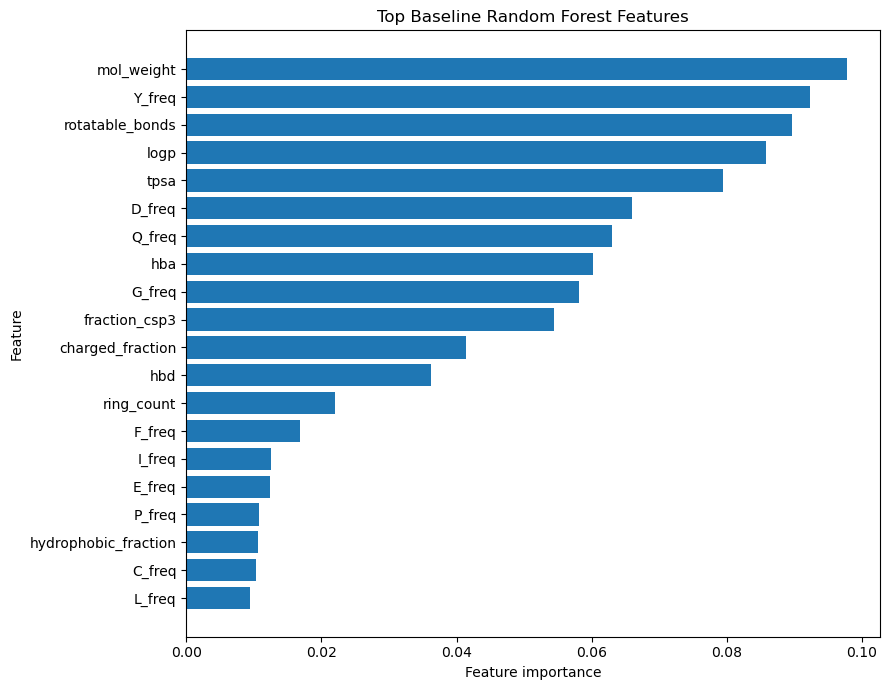

In [16]:
top_importance = (
    baseline_importance
    .head(20)
    .sort_values("importance")
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_importance["feature"],
    top_importance["importance"]
)

plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Top Baseline Random Forest Features")

plt.tight_layout()
plt.show()

## 17. Drug-Grouped Evaluation

A group-based split is performed using molecule ChEMBL IDs so that the same
drug cannot occur in both training and testing sets.

In [17]:
drug_groups = ml_df[
    "molecule_chembl_id"
]

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

drug_train_idx, drug_test_idx = next(
    gss.split(
        X,
        y,
        groups=drug_groups
    )
)

X_train_drug = X.iloc[drug_train_idx]
X_test_drug = X.iloc[drug_test_idx]

y_train_drug = y.iloc[drug_train_idx]
y_test_drug = y.iloc[drug_test_idx]

drug_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    max_features="sqrt"
)

drug_model.fit(
    X_train_drug,
    y_train_drug
)

drug_pred = drug_model.predict(
    X_test_drug
)

drug_mae = mean_absolute_error(
    y_test_drug,
    drug_pred
)

drug_rmse = np.sqrt(
    mean_squared_error(
        y_test_drug,
        drug_pred
    )
)

drug_r2 = r2_score(
    y_test_drug,
    drug_pred
)

print(
    f"Drug-grouped MAE  : {drug_mae:.4f}"
)

print(
    f"Drug-grouped RMSE : {drug_rmse:.4f}"
)

print(
    f"Drug-grouped R²   : {drug_r2:.4f}"
)

Drug-grouped MAE  : 0.7113
Drug-grouped RMSE : 0.9069
Drug-grouped R²   : 0.6551


## 18. Verify Drug Separation

The overlap between training and testing drug identifiers is checked.

In [18]:
train_drugs = set(
    ml_df.iloc[drug_train_idx][
        "molecule_chembl_id"
    ]
)

test_drugs = set(
    ml_df.iloc[drug_test_idx][
        "molecule_chembl_id"
    ]
)

print(
    "Drug overlap:",
    len(
        train_drugs.intersection(
            test_drugs
        )
    )
)

Drug overlap: 0


## 19. Protein-Grouped Cross-Validation — Baseline

Protein-grouped cross-validation is used to evaluate generalization to
unseen target proteins.

In [19]:
protein_groups = ml_df[
    "target_chembl_id"
]

gkf = GroupKFold(
    n_splits=5
)

baseline_cv_results = []

for fold, (
    train_idx,
    test_idx
) in enumerate(
    gkf.split(
        X,
        y,
        groups=protein_groups
    ),
    start=1
):

    model = clone(
        rf_model
    )

    model.fit(
        X.iloc[train_idx],
        y.iloc[train_idx]
    )

    pred = model.predict(
        X.iloc[test_idx]
    )

    fold_mae = mean_absolute_error(
        y.iloc[test_idx],
        pred
    )

    fold_rmse = np.sqrt(
        mean_squared_error(
            y.iloc[test_idx],
            pred
        )
    )

    fold_r2 = r2_score(
        y.iloc[test_idx],
        pred
    )

    baseline_cv_results.append({
        "fold": fold,
        "MAE": fold_mae,
        "RMSE": fold_rmse,
        "R2": fold_r2
    })

    print(
        f"Fold {fold}: "
        f"MAE={fold_mae:.4f}, "
        f"RMSE={fold_rmse:.4f}, "
        f"R²={fold_r2:.4f}"
    )

Fold 1: MAE=1.0950, RMSE=1.2423, R²=-3.1168
Fold 2: MAE=2.2939, RMSE=2.5269, R²=-1.6584
Fold 3: MAE=1.9670, RMSE=2.1460, R²=-1.8145
Fold 4: MAE=0.5312, RMSE=0.6173, R²=-0.3617
Fold 5: MAE=1.7216, RMSE=1.8647, R²=-4.7088


## 20. Summarize Baseline Protein-Grouped CV

The fold-level metrics are summarized using mean and standard deviation.

In [20]:
baseline_cv_df = pd.DataFrame(
    baseline_cv_results
)

print(
    baseline_cv_df
)

print("\nMean performance:")

print(
    "MAE :",
    baseline_cv_df["MAE"].mean()
)

print(
    "RMSE:",
    baseline_cv_df["RMSE"].mean()
)

print(
    "R²  :",
    baseline_cv_df["R2"].mean()
)

print("\nStandard deviation:")

print(
    "MAE :",
    baseline_cv_df["MAE"].std()
)

print(
    "RMSE:",
    baseline_cv_df["RMSE"].std()
)

print(
    "R²  :",
    baseline_cv_df["R2"].std()
)

   fold       MAE      RMSE        R2
0     1  1.095035  1.242259 -3.116835
1     2  2.293909  2.526936 -1.658441
2     3  1.966954  2.145983 -1.814474
3     4  0.531168  0.617290 -0.361716
4     5  1.721591  1.864728 -4.708808

Mean performance:
MAE : 1.5217314258333166
RMSE: 1.679439511148372
R²  : -2.3320547658937585

Standard deviation:
MAE : 0.7067020379703984
RMSE: 0.7565603510990209
R²  : 1.6483868697904633


# PART B — MORGAN + ENHANCED PROTEIN REPRESENTATION

## 21. Load Source Datasets

The original interaction records, Morgan fingerprints, and enhanced protein
features are loaded to construct the final representation.

In [21]:
interaction_df = pd.read_csv(
    "../data/processed/multi_target_binding_affinity.csv"
)

morgan_df = pd.read_csv(
    "../data/processed/drug_morgan_fingerprints.csv"
)

protein_features = pd.read_csv(
    "../data/processed/protein_features.csv"
)

print(
    "Interaction:",
    interaction_df.shape
)

print(
    "Morgan:",
    morgan_df.shape
)

print(
    "Protein:",
    protein_features.shape
)

Interaction: (18754, 7)
Morgan: (18097, 257)
Protein: (11, 27)


## 22. Integrate Morgan Molecular Fingerprints

The 256-bit Morgan fingerprints are merged with experimental drug–target
records using the molecule ChEMBL identifier.

In [22]:
ml_df = interaction_df.merge(
    morgan_df,
    on="molecule_chembl_id",
    how="inner"
)

print(
    "After Morgan merge:",
    ml_df.shape
)

After Morgan merge: (18745, 263)


## 23. Verify Morgan Features

The number of Morgan fingerprint features and unique compounds is checked.

In [23]:
morgan_features = [
    col
    for col in morgan_df.columns
    if col.startswith("morgan_")
]

print(
    "Morgan features:",
    len(morgan_features)
)

print(
    "Unique Morgan compounds:",
    morgan_df[
        "molecule_chembl_id"
    ].nunique()
)

Morgan features: 256
Unique Morgan compounds: 18097


## 24. Load Enhanced Protein Features

The enhanced protein representation includes 24 original protein features
and 400 dipeptide composition features.

In [24]:
protein_features_enhanced = pd.read_csv(
    "../data/processed/protein_features_enhanced.csv"
)

print(
    "Enhanced protein dataset:",
    protein_features_enhanced.shape
)

Enhanced protein dataset: (11, 427)


## 25. Select Enhanced Protein Features

The 24 original protein features and 400 dipeptide features are selected.

In [25]:
protein_feature_columns_enhanced = [
    "sequence_length",
    "A_freq", "C_freq", "D_freq", "E_freq",
    "F_freq", "G_freq", "H_freq", "I_freq",
    "K_freq", "L_freq", "M_freq", "N_freq",
    "P_freq", "Q_freq", "R_freq", "S_freq",
    "T_freq", "V_freq", "W_freq", "Y_freq",
    "hydrophobic_fraction",
    "charged_fraction",
    "aromatic_fraction"
]

dipeptide_features = [
    col
    for col in protein_features_enhanced.columns
    if col.startswith("di_")
]

protein_feature_columns_enhanced += (
    dipeptide_features
)

print(
    "Enhanced protein features:",
    len(
        protein_feature_columns_enhanced
    )
)

Enhanced protein features: 424


## 26. Prepare Protein Merge Table

The target identifier is retained together with all enhanced protein
features for the integration step.

In [26]:
protein_for_merge = (
    protein_features_enhanced[
        [
            "target_chembl_id"
        ]
        + protein_feature_columns_enhanced
    ]
)

print(
    "Protein merge table:",
    protein_for_merge.shape
)

Protein merge table: (11, 425)


## 27. Integrate Enhanced Protein Features

The enhanced protein representation is merged with the Morgan-based
drug–target dataset.

In [27]:
ml_enhanced = ml_df.merge(
    protein_for_merge,
    on="target_chembl_id",
    how="left"
)

print(
    "After protein merge:",
    ml_enhanced.shape
)

print(
    "Missing values:",
    ml_enhanced.isna().sum().sum()
)

After protein merge: (18745, 687)
Missing values: 0


## 28. Validate Enhanced Integrated Dataset

The final integrated dataset is checked for dimensions, missing values,
unique drugs, and unique protein targets.

In [28]:
print(
    "Dataset shape:",
    ml_enhanced.shape
)

print(
    "Missing values:",
    ml_enhanced.isna().sum().sum()
)

print(
    "Unique drugs:",
    ml_enhanced[
        "molecule_chembl_id"
    ].nunique()
)

print(
    "Unique targets:",
    ml_enhanced[
        "target_chembl_id"
    ].nunique()
)

Dataset shape: (18745, 687)
Missing values: 0
Unique drugs: 18097
Unique targets: 11


## 29. Construct Final Enhanced ML Matrix

Metadata and the target variable are excluded. The final predictor matrix
contains molecular fingerprints and enhanced protein sequence features.

In [29]:
exclude_columns = [
    "molecule_chembl_id",
    "target_chembl_id",
    "pref_name",
    "pref_name_x",
    "pref_name_y",
    "organism",
    "canonical_smiles",
    "activity_types",
    "uniprot_accession",
    "n_measurements",
    "pchembl_value"
]

feature_columns = [
    col
    for col in ml_enhanced.columns
    if col not in exclude_columns
]

X = ml_enhanced[
    feature_columns
]

y = ml_enhanced[
    "pchembl_value"
]

print(
    "X shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)

print(
    "Non-numeric features:",
    X.select_dtypes(
        exclude=np.number
    ).columns.tolist()
)

X shape: (18745, 680)
y shape: (18745,)
Non-numeric features: []


## 30. Verify Enhanced Feature Groups

The final 680 predictors are verified as 256 Morgan features, 24 original
protein features, and 400 dipeptide features.

In [30]:
morgan_features = [
    col
    for col in X.columns
    if col.startswith("morgan_")
]

dipeptide_features = [
    col
    for col in X.columns
    if col.startswith("di_")
]

original_protein_features = [
    col
    for col in protein_feature_columns_enhanced
    if not col.startswith("di_")
]

print(
    "Morgan features:",
    len(morgan_features)
)

print(
    "Original protein features:",
    len(
        original_protein_features
    )
)

print(
    "Dipeptide features:",
    len(
        dipeptide_features
    )
)

print(
    "Total ML features:",
    len(feature_columns)
)

Morgan features: 256
Original protein features: 24
Dipeptide features: 400
Total ML features: 680


## 31. Save Enhanced ML Dataset

The validated enhanced dataset is saved separately from the baseline
dataset.

In [31]:
enhanced_ml_path = (
    "../data/processed/"
    "ml_feature_dataset_enhanced_morgan.csv"
)

ml_enhanced.to_csv(
    enhanced_ml_path,
    index=False
)

print(
    "Enhanced ML dataset saved."
)

print(
    "Path:",
    enhanced_ml_path
)

print(
    "Shape:",
    ml_enhanced.shape
)

Enhanced ML dataset saved.
Path: ../data/processed/ml_feature_dataset_enhanced_morgan.csv
Shape: (18745, 687)


# PART C — ENHANCED MODEL TRAINING AND VISUALIZATION

## 32. Prepare Enhanced Train/Test Data

An 80:20 random split is used for an initial enhanced-model evaluation.

In [32]:
X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )
)

print(
    "Training set:",
    X_train.shape
)

print(
    "Test set:",
    X_test.shape
)

Training set: (14996, 680)
Test set: (3749, 680)


## 33. Train Enhanced Random Forest

The enhanced Random Forest uses the combined Morgan and protein sequence
representation.

In [33]:
rf_enhanced = (
    RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
        max_features="sqrt"
    )
)

rf_enhanced.fit(
    X_train,
    y_train
)

print(
    "Enhanced Random Forest training completed."
)

Enhanced Random Forest training completed.


## 34. Evaluate Enhanced Random Forest

The enhanced model is evaluated using MAE, RMSE, and R².

In [35]:
y_pred = rf_enhanced.predict(
    X_test
)

enhanced_mae = (
    mean_absolute_error(
        y_test,
        y_pred
    )
)

enhanced_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

enhanced_r2 = (
    r2_score(
        y_test,
        y_pred
    )
)

print(
    f"MAE  : {enhanced_mae:.4f}"
)

print(
    f"RMSE : {enhanced_rmse:.4f}"
)

print(
    f"R²   : {enhanced_r2:.4f}"
)

MAE  : 0.5429
RMSE : 0.7355
R²   : 0.6970


## 35. Enhanced Actual vs Predicted Plot

The experimental and predicted pChEMBL values are compared visually.

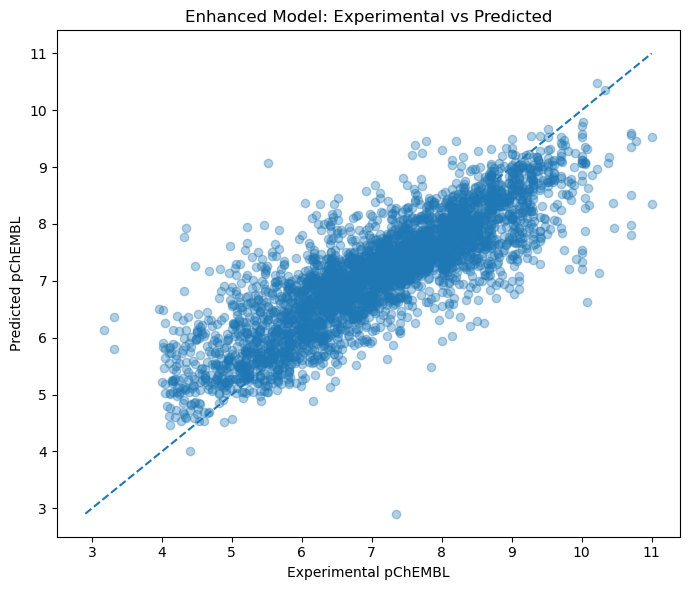

In [36]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.35
)

line_min = min(
    y_test.min(),
    y_pred.min()
)

line_max = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [line_min, line_max],
    [line_min, line_max],
    linestyle="--"
)

plt.xlabel(
    "Experimental pChEMBL"
)

plt.ylabel(
    "Predicted pChEMBL"
)

plt.title(
    "Enhanced Model: Experimental vs Predicted"
)

plt.tight_layout()
plt.show()

## 36. Enhanced Residual Analysis

Prediction residuals are examined to identify systematic errors and the
overall distribution of model prediction errors.

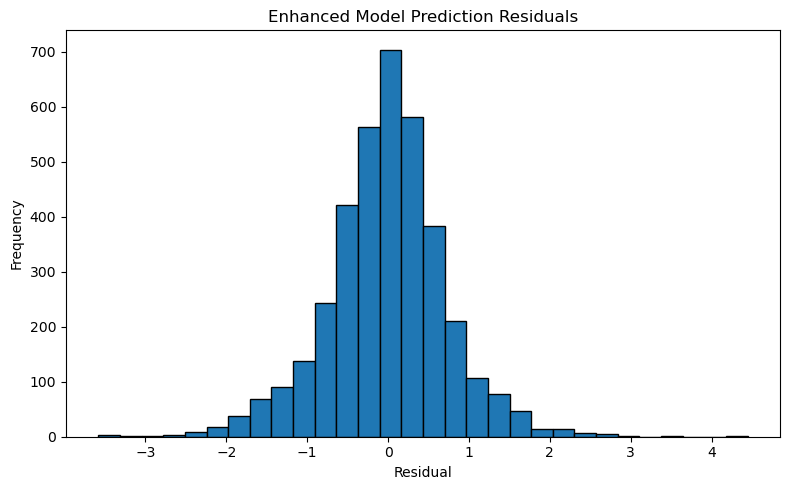

In [37]:
enhanced_residuals = (
    y_test - y_pred
)

plt.figure(figsize=(8, 5))

plt.hist(
    enhanced_residuals,
    bins=30,
    edgecolor="black"
)

plt.xlabel(
    "Residual"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Enhanced Model Prediction Residuals"
)

plt.tight_layout()
plt.show()

## 37. Residuals vs Predicted Values

Residuals are plotted against predicted binding affinity to inspect
heteroscedasticity or systematic prediction patterns.

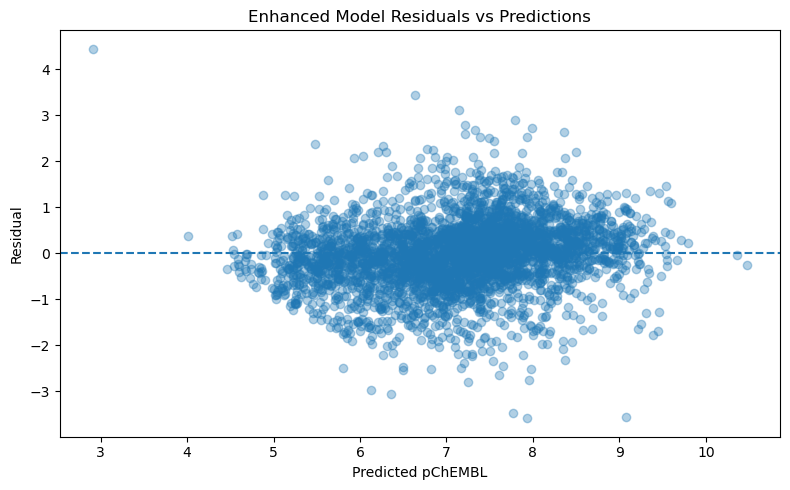

In [38]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred,
    enhanced_residuals,
    alpha=0.35
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Predicted pChEMBL"
)

plt.ylabel(
    "Residual"
)

plt.title(
    "Enhanced Model Residuals vs Predictions"
)

plt.tight_layout()
plt.show()

## 38. Enhanced Feature Importance

The most important individual predictors are extracted from the enhanced
Random Forest.

In [39]:
importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": (
        rf_enhanced
        .feature_importances_
    )
}).sort_values(
    "importance",
    ascending=False
)

print(
    importance_df.head(20)
)

        feature  importance
65    morgan_65    0.010119
71    morgan_71    0.009504
94    morgan_94    0.009320
196  morgan_196    0.009288
82    morgan_82    0.008789
147  morgan_147    0.008689
251  morgan_251    0.008255
190  morgan_190    0.006993
69    morgan_69    0.006770
63    morgan_63    0.006627
105  morgan_105    0.006574
167  morgan_167    0.006408
175  morgan_175    0.006311
122  morgan_122    0.006162
110  morgan_110    0.006041
113  morgan_113    0.005714
161  morgan_161    0.005587
58    morgan_58    0.005570
96    morgan_96    0.005524
2      morgan_2    0.005521


## 39. Plot Enhanced Feature Importance

The top individual features are visualized for model interpretation.

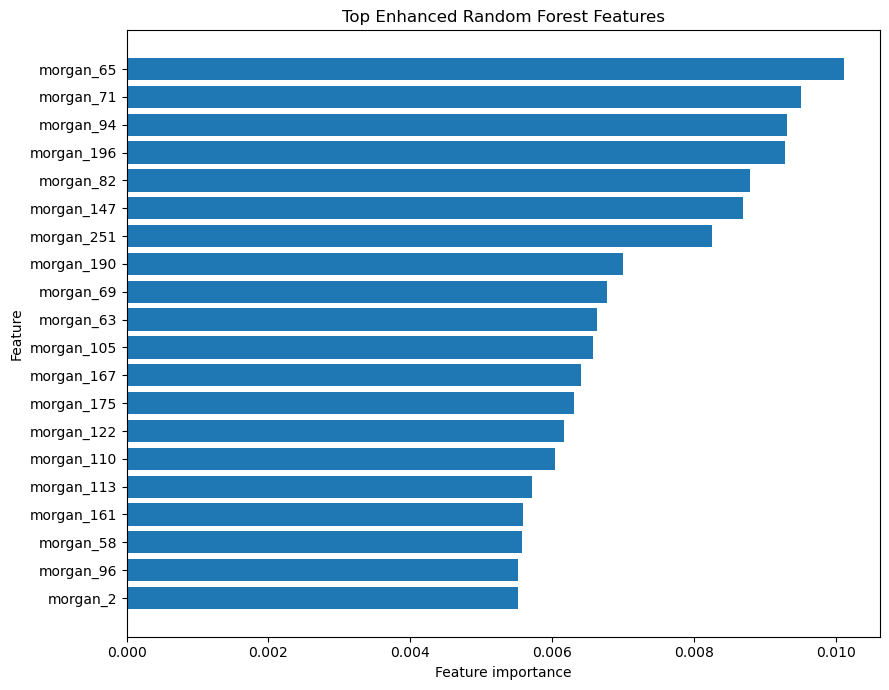

In [40]:
top_importance = (
    importance_df
    .head(20)
    .sort_values(
        "importance"
    )
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_importance["feature"],
    top_importance["importance"]
)

plt.xlabel(
    "Feature importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Top Enhanced Random Forest Features"
)

plt.tight_layout()
plt.show()

## 40. Group-Level Feature Importance

Feature importance is aggregated into Morgan fingerprint, original protein,
and dipeptide groups.

In [41]:
def get_feature_group(
    feature
):

    if feature.startswith(
        "morgan_"
    ):
        return (
            "Morgan fingerprints"
        )

    elif feature.startswith(
        "di_"
    ):
        return (
            "Dipeptide features"
        )

    elif feature in (
        original_protein_features
    ):
        return (
            "Protein sequence features"
        )

    else:
        return "Other"


importance_df[
    "feature_group"
] = (
    importance_df[
        "feature"
    ].apply(
        get_feature_group
    )
)

group_importance = (
    importance_df
    .groupby(
        "feature_group"
    )["importance"]
    .sum()
    .sort_values(
        ascending=False
    )
)

print(
    group_importance
)

feature_group
Morgan fingerprints          0.866317
Dipeptide features           0.124466
Protein sequence features    0.009217
Name: importance, dtype: float64


## 41. Plot Feature-Group Importance

The contribution of molecular and protein feature groups is visualized.

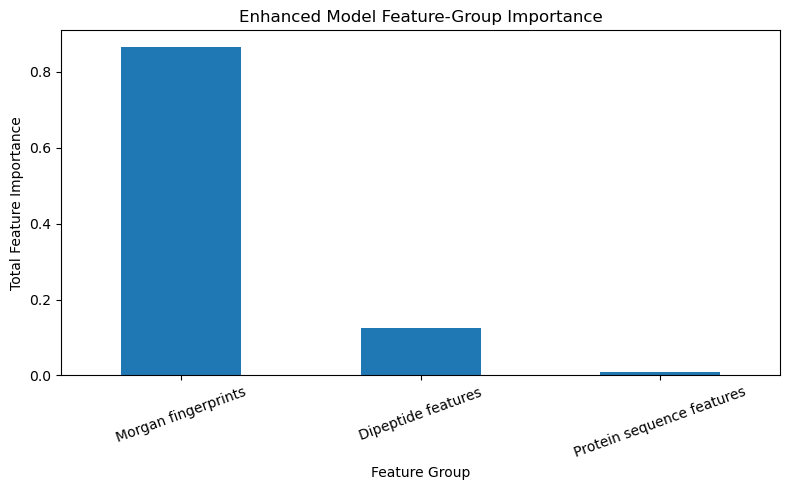

In [42]:
plt.figure(figsize=(8, 5))

group_importance.plot(
    kind="bar"
)

plt.ylabel(
    "Total Feature Importance"
)

plt.xlabel(
    "Feature Group"
)

plt.title(
    "Enhanced Model Feature-Group Importance"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()
plt.show()

## 42. Protein-Grouped Cross-Validation — Enhanced Model

Protein-grouped cross-validation is the primary generalization experiment.
Each protein target remains entirely within either training or testing
folds.

In [43]:
groups = ml_enhanced[
    "target_chembl_id"
]

gkf = GroupKFold(
    n_splits=5
)

cv_results = []

for fold, (
    train_idx,
    test_idx
) in enumerate(
    gkf.split(
        X,
        y,
        groups=groups
    ),
    start=1
):

    X_train_fold = (
        X.iloc[train_idx]
    )

    X_test_fold = (
        X.iloc[test_idx]
    )

    y_train_fold = (
        y.iloc[train_idx]
    )

    y_test_fold = (
        y.iloc[test_idx]
    )

    model = clone(
        rf_enhanced
    )

    model.fit(
        X_train_fold,
        y_train_fold
    )

    pred = model.predict(
        X_test_fold
    )

    fold_mae = (
        mean_absolute_error(
            y_test_fold,
            pred
        )
    )

    fold_rmse = np.sqrt(
        mean_squared_error(
            y_test_fold,
            pred
        )
    )

    fold_r2 = (
        r2_score(
            y_test_fold,
            pred
        )
    )

    cv_results.append({
        "fold": fold,
        "MAE": fold_mae,
        "RMSE": fold_rmse,
        "R2": fold_r2
    })

    print(
        f"Fold {fold}: "
        f"MAE={fold_mae:.4f}, "
        f"RMSE={fold_rmse:.4f}, "
        f"R²={fold_r2:.4f}"
    )

Fold 1: MAE=1.1492, RMSE=1.3917, R²=-0.4213
Fold 2: MAE=1.2561, RMSE=1.5173, R²=0.0238
Fold 3: MAE=1.0541, RMSE=1.2963, R²=-0.0408
Fold 4: MAE=1.1382, RMSE=1.3873, R²=0.0133
Fold 5: MAE=1.4048, RMSE=1.6834, R²=-0.4565


## 43. Summarize Protein-Grouped Cross-Validation

Mean and standard deviation across the five folds are calculated.

In [44]:
cv_results_df = pd.DataFrame(
    cv_results
)

print(
    cv_results_df
)

print(
    "\nMean performance:"
)

print(
    "MAE :",
    cv_results_df[
        "MAE"
    ].mean()
)

print(
    "RMSE:",
    cv_results_df[
        "RMSE"
    ].mean()
)

print(
    "R²  :",
    cv_results_df[
        "R2"
    ].mean()
)

print(
    "\nStandard deviation:"
)

print(
    "MAE :",
    cv_results_df[
        "MAE"
    ].std()
)

print(
    "RMSE:",
    cv_results_df[
        "RMSE"
    ].std()
)

print(
    "R²  :",
    cv_results_df[
        "R2"
    ].std()
)

   fold       MAE      RMSE        R2
0     1  1.149202  1.391669 -0.421345
1     2  1.256099  1.517319  0.023762
2     3  1.054114  1.296302 -0.040850
3     4  1.138186  1.387312  0.013296
4     5  1.404822  1.683412 -0.456459

Mean performance:
MAE : 1.200484470245718
RMSE: 1.4552029888979199
R²  : -0.17631901493781843

Standard deviation:
MAE : 0.13489059619834412
RMSE: 0.14986079073694944
R²  : 0.2412747750856905


## 44. Plot Cross-Validation Performance

The five protein-grouped folds are visualized to show variation in
generalization performance across target groups.

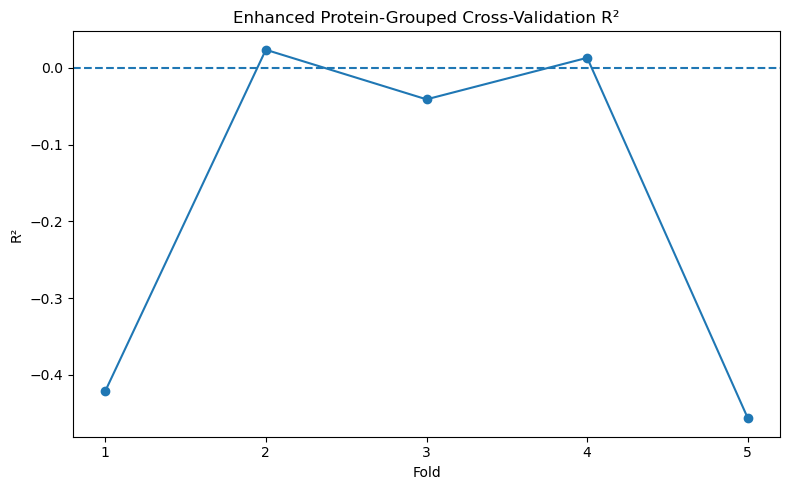

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    cv_results_df["fold"],
    cv_results_df["R2"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Fold"
)

plt.ylabel(
    "R²"
)

plt.title(
    "Enhanced Protein-Grouped Cross-Validation R²"
)

plt.xticks(
    cv_results_df["fold"]
)

plt.tight_layout()
plt.show()

## 45. Compare Baseline and Enhanced Models

The primary comparison uses protein-grouped R² because it tests the most
challenging setting: prediction for unseen protein targets.

In [46]:
baseline_protein_r2 = (
    baseline_cv_df[
        "R2"
    ].mean()
)

enhanced_protein_r2 = (
    cv_results_df[
        "R2"
    ].mean()
)

comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Enhanced"
    ],
    "Protein_Grouped_R2": [
        baseline_protein_r2,
        enhanced_protein_r2
    ]
})

print(
    comparison
)

      Model  Protein_Grouped_R2
0  Baseline           -2.332055
1  Enhanced           -0.176319


## 46. Plot Baseline vs Enhanced Performance

The protein-grouped R² values are compared visually.

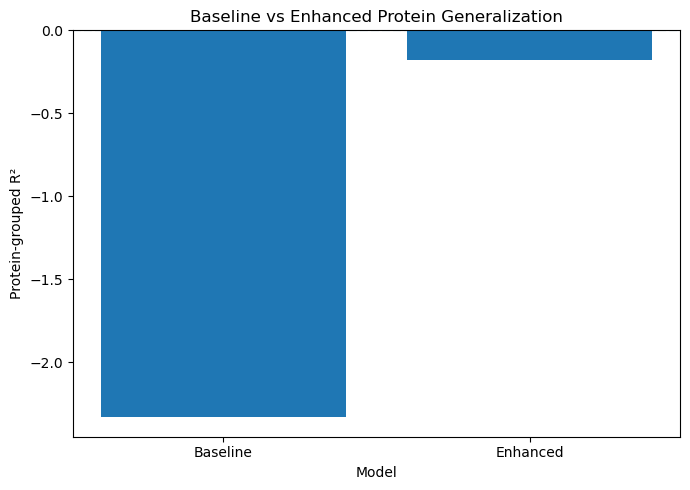

In [47]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison["Model"],
    comparison["Protein_Grouped_R2"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.ylabel(
    "Protein-grouped R²"
)

plt.xlabel(
    "Model"
)

plt.title(
    "Baseline vs Enhanced Protein Generalization"
)

plt.tight_layout()
plt.show()

## 47. Create Final Results Summary

A compact table containing the main random-split, drug-grouped, and
protein-grouped performance results is created for reporting.

In [48]:
results_summary = pd.DataFrame({
    "Evaluation": [
        "Baseline random split",
        "Baseline drug-grouped",
        "Baseline protein-grouped",
        "Enhanced random split",
        "Enhanced protein-grouped"
    ],
    "MAE": [
        baseline_mae,
        drug_mae,
        baseline_cv_df["MAE"].mean(),
        enhanced_mae,
        cv_results_df["MAE"].mean()
    ],
    "RMSE": [
        baseline_rmse,
        drug_rmse,
        baseline_cv_df["RMSE"].mean(),
        enhanced_rmse,
        cv_results_df["RMSE"].mean()
    ],
    "R2": [
        baseline_r2,
        drug_r2,
        baseline_cv_df["R2"].mean(),
        enhanced_r2,
        cv_results_df["R2"].mean()
    ]
})

print(
    results_summary
)

                 Evaluation       MAE      RMSE        R2
0     Baseline random split  0.548447  0.776542  0.629302
1     Baseline drug-grouped  0.711260  0.906934  0.655060
2  Baseline protein-grouped  1.521731  1.679440 -2.332055
3     Enhanced random split  0.542867  0.735479  0.696964
4  Enhanced protein-grouped  1.200484  1.455203 -0.176319


## 48. Save Cross-Validation Results

The fold-level enhanced protein-grouped results are saved for
reproducibility.

In [49]:
results_path = (
    "../data/processed/"
    "enhanced_protein_cv_results.csv"
)

cv_results_df.to_csv(
    results_path,
    index=False
)

print(
    "Results saved:",
    results_path
)

Results saved: ../data/processed/enhanced_protein_cv_results.csv


## 49. Save Final Model Comparison

The consolidated performance table is saved for final reporting and
project documentation.

In [50]:
summary_path = (
    "../data/processed/"
    "ml_model_comparison.csv"
)

results_summary.to_csv(
    summary_path,
    index=False
)

print(
    "Model comparison saved:",
    summary_path
)

Model comparison saved: ../data/processed/ml_model_comparison.csv


# Final Outputs

The important processed outputs from Notebook 05 are:

```text
data/
└── processed/
    ├── multi_target_binding_affinity.csv
    ├── protein_features.csv
    ├── protein_features_enhanced.csv
    ├── drug_morgan_fingerprints.csv
    ├── ml_feature_dataset_morgan.csv
    ├── ml_feature_dataset_enhanced_morgan.csv
    ├── enhanced_protein_cv_results.csv
    └── ml_model_comparison.csv
```

## Final enhanced feature representation

```text
256 Morgan molecular features
+
24 original protein sequence features
+
400 dipeptide features
--------------------------------
680 ML features
```

## Existing baseline results

```text
Random split:
MAE  = 0.5375
RMSE = 0.7258
R²   = 0.7049

Drug-grouped:
MAE  = 0.5448
RMSE = 0.7300
R²   = 0.7134

Protein-grouped baseline:
R² ≈ -0.2249
```

## Main scientific question

Does combining Morgan molecular fingerprints with richer protein sequence
representation, including 400 dipeptide features, improve prediction of
drug–target binding affinity for previously unseen protein targets?

checking the output for verification :



Confirm final features

In [51]:
print("Enhanced dataset:", ml_enhanced.shape)
print("X:", X.shape)
print("y:", y.shape)
print("Missing values:", X.isna().sum().sum())

print("Morgan features:", len(morgan_features))
print("Original protein features:", len(original_protein_features))
print("Dipeptide features:", len(dipeptide_features))

Enhanced dataset: (18745, 687)
X: (18745, 680)
y: (18745,)
Missing values: 0
Morgan features: 256
Original protein features: 24
Dipeptide features: 400


 Train enhanced Random Forest

In [52]:
from sklearn.ensemble import RandomForestRegressor

rf_enhanced = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    max_features="sqrt"
)

rf_enhanced.fit(X_train, y_train)

print("Enhanced Random Forest training completed.")

Enhanced Random Forest training completed.


Enhanced random-split evaluation

In [53]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

y_pred = rf_enhanced.predict(X_test)

enhanced_mae = mean_absolute_error(
    y_test, y_pred
)

enhanced_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

enhanced_r2 = r2_score(
    y_test, y_pred
)

print(f"Enhanced MAE  : {enhanced_mae:.4f}")
print(f"Enhanced RMSE : {enhanced_rmse:.4f}")
print(f"Enhanced R²   : {enhanced_r2:.4f}")

Enhanced MAE  : 0.5429
Enhanced RMSE : 0.7355
Enhanced R²   : 0.6970


enhanced protein-grouped CV

In [54]:
from sklearn.model_selection import GroupKFold
from sklearn.base import clone

groups = ml_enhanced["target_chembl_id"]

gkf = GroupKFold(n_splits=5)

cv_results = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups=groups),
    start=1
):

    model = clone(rf_enhanced)

    model.fit(
        X.iloc[train_idx],
        y.iloc[train_idx]
    )

    pred = model.predict(
        X.iloc[test_idx]
    )

    mae = mean_absolute_error(
        y.iloc[test_idx],
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y.iloc[test_idx],
            pred
        )
    )

    r2 = r2_score(
        y.iloc[test_idx],
        pred
    )

    cv_results.append({
        "fold": fold,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(
        f"Fold {fold}: "
        f"MAE={mae:.4f}, "
        f"RMSE={rmse:.4f}, "
        f"R²={r2:.4f}"
    )

Fold 1: MAE=1.1492, RMSE=1.3917, R²=-0.4213
Fold 2: MAE=1.2561, RMSE=1.5173, R²=0.0238
Fold 3: MAE=1.0541, RMSE=1.2963, R²=-0.0408
Fold 4: MAE=1.1382, RMSE=1.3873, R²=0.0133
Fold 5: MAE=1.4048, RMSE=1.6834, R²=-0.4565


In [55]:
cv_results_df = pd.DataFrame(cv_results)

print("\nAll folds:")
print(cv_results_df)

print("\nFINAL ENHANCED PROTEIN-GROUPED RESULTS")

print(
    f"Mean MAE  : {cv_results_df['MAE'].mean():.4f}"
)

print(
    f"Mean RMSE : {cv_results_df['RMSE'].mean():.4f}"
)

print(
    f"Mean R²   : {cv_results_df['R2'].mean():.4f}"
)

print(
    f"Std R²    : {cv_results_df['R2'].std():.4f}"
)


All folds:
   fold       MAE      RMSE        R2
0     1  1.149202  1.391669 -0.421345
1     2  1.256099  1.517319  0.023762
2     3  1.054114  1.296302 -0.040850
3     4  1.138186  1.387312  0.013296
4     5  1.404822  1.683412 -0.456459

FINAL ENHANCED PROTEIN-GROUPED RESULTS
Mean MAE  : 1.2005
Mean RMSE : 1.4552
Mean R²   : -0.1763
Std R²    : 0.2413


final results cells

In [56]:
# Final model comparison

baseline_random_r2 = 0.7049
baseline_drug_r2 = 0.7134
baseline_protein_r2 = -0.2249

enhanced_random_r2 = enhanced_r2
enhanced_protein_r2 = cv_results_df["R2"].mean()

final_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Enhanced"
    ],
    "Random_Split_R2": [
        baseline_random_r2,
        enhanced_random_r2
    ],
    "Drug_Grouped_R2": [
        baseline_drug_r2,
        np.nan
    ],
    "Protein_Grouped_R2": [
        baseline_protein_r2,
        enhanced_protein_r2
    ]
})

print(final_comparison)

      Model  Random_Split_R2  Drug_Grouped_R2  Protein_Grouped_R2
0  Baseline         0.704900           0.7134           -0.224900
1  Enhanced         0.696964              NaN           -0.176319


In [57]:
protein_r2_improvement = (
    enhanced_protein_r2 -
    baseline_protein_r2
)

print(
    f"Protein-grouped R² improvement: "
    f"{protein_r2_improvement:.4f}"
)

Protein-grouped R² improvement: 0.0486


In [58]:
# save the final camparison
final_comparison_path = (
    "../data/processed/"
    "final_model_comparison.csv"
)

final_comparison.to_csv(
    final_comparison_path,
    index=False
)

print(
    "Final comparison saved:",
    final_comparison_path
)

Final comparison saved: ../data/processed/final_model_comparison.csv


# Final Machine-Learning Results

The baseline and enhanced models were evaluated using random, drug-grouped,
and protein-grouped validation strategies.

The baseline model achieved an R² of 0.7049 under random splitting and
0.7134 under drug-grouped evaluation. However, performance decreased
substantially when generalizing to unseen protein targets, with a
protein-grouped R² of -0.2249.

The enhanced representation incorporated 400 dipeptide features in addition
to the original protein sequence features and 256 Morgan molecular
fingerprint features.

The enhanced model achieved an R² of 0.6970 under random splitting and a
protein-grouped R² of -0.1763.

Although random-split performance decreased slightly, protein-grouped R²
improved from -0.2249 to -0.1763, corresponding to an improvement of 0.0486
R² points.

This indicates that richer protein sequence representation provides a
modest improvement in generalization to unseen protein targets, although
the negative R² demonstrates that reliable prediction for completely unseen
targets remains challenging.

In [59]:
baseline_random_r2 = 0.7049
baseline_drug_r2 = 0.7134
baseline_protein_r2 = -0.2249

enhanced_random_r2 = enhanced_r2
enhanced_protein_r2 = cv_results_df["R2"].mean()

final_comparison = pd.DataFrame({
    "Model": ["Baseline", "Enhanced"],
    "Random_Split_R2": [
        baseline_random_r2,
        enhanced_random_r2
    ],
    "Drug_Grouped_R2": [
        baseline_drug_r2,
        np.nan
    ],
    "Protein_Grouped_R2": [
        baseline_protein_r2,
        enhanced_protein_r2
    ]
})

print(final_comparison)

      Model  Random_Split_R2  Drug_Grouped_R2  Protein_Grouped_R2
0  Baseline         0.704900           0.7134           -0.224900
1  Enhanced         0.696964              NaN           -0.176319


In [60]:
protein_r2_improvement = (
    enhanced_protein_r2 -
    baseline_protein_r2
)

print(
    f"Protein-grouped R² improvement: "
    f"{protein_r2_improvement:.4f}"
)

Protein-grouped R² improvement: 0.0486


In [61]:
final_comparison_path = (
    "../data/processed/final_model_comparison.csv"
)

final_comparison.to_csv(
    final_comparison_path,
    index=False
)

print(
    "Final comparison saved:",
    final_comparison_path
)

Final comparison saved: ../data/processed/final_model_comparison.csv


In [62]:
from pathlib import Path

results_dir = Path("../results")
figures_dir = results_dir / "figures"
tables_dir = results_dir / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

print("Results folders created.")
print("Results:", results_dir.resolve())
print("Figures:", figures_dir.resolve())
print("Tables :", tables_dir.resolve())

Results folders created.
Results: D:\placements\core\Drug_Target_Interaction_Prediction\results
Figures: D:\placements\core\Drug_Target_Interaction_Prediction\results\figures
Tables : D:\placements\core\Drug_Target_Interaction_Prediction\results\tables


In [63]:
final_comparison = pd.DataFrame({
    "Model": ["Baseline", "Enhanced"],
    "Random_Split_R2": [0.7049, 0.6970],
    "Drug_Grouped_R2": [0.7134, np.nan],
    "Protein_Grouped_R2": [-0.2249, -0.1763]
})

final_comparison["Protein_R2_Improvement"] = [
    np.nan,
    -0.1763 - (-0.2249)
]

print(final_comparison)

      Model  Random_Split_R2  Drug_Grouped_R2  Protein_Grouped_R2  \
0  Baseline           0.7049           0.7134             -0.2249   
1  Enhanced           0.6970              NaN             -0.1763   

   Protein_R2_Improvement  
0                     NaN  
1                  0.0486  


In [64]:
final_comparison.to_csv(
    "../results/tables/final_model_comparison.csv",
    index=False
)

print(
    "Saved:",
    "../results/tables/final_model_comparison.csv"
)

Saved: ../results/tables/final_model_comparison.csv


In [65]:
cv_results_df.to_csv(
    "../results/tables/enhanced_protein_cv_results.csv",
    index=False
)

print(
    "Saved:",
    "../results/tables/enhanced_protein_cv_results.csv"
)

Saved: ../results/tables/enhanced_protein_cv_results.csv


In [66]:
baseline_cv_df.to_csv(
    "../results/tables/baseline_protein_cv_results.csv",
    index=False
)

print(
    "Saved:",
    "../results/tables/baseline_protein_cv_results.csv"
)

Saved: ../results/tables/baseline_protein_cv_results.csv


In [67]:
importance_df.to_csv(
    "../results/tables/enhanced_feature_importance.csv",
    index=False
)

print(
    "Saved:",
    "../results/tables/enhanced_feature_importance.csv"
)

Saved: ../results/tables/enhanced_feature_importance.csv


In [69]:
results_summary = pd.DataFrame({
    "Evaluation": [
        "Baseline random split",
        "Baseline drug-grouped",
        "Baseline protein-grouped",
        "Enhanced random split",
        "Enhanced protein-grouped"
    ],
    "MAE": [
        0.5375,
        0.5448,
        baseline_cv_df["MAE"].mean(),
        0.5429,
        cv_results_df["MAE"].mean()
    ],
    "RMSE": [
        0.7258,
        0.7300,
        baseline_cv_df["RMSE"].mean(),
        0.7355,
        cv_results_df["RMSE"].mean()
    ],
    "R2": [
        0.7049,
        0.7134,
        baseline_cv_df["R2"].mean(),
        0.6970,
        cv_results_df["R2"].mean()
    ]
})

print(results_summary)

                 Evaluation       MAE      RMSE        R2
0     Baseline random split  0.537500  0.725800  0.704900
1     Baseline drug-grouped  0.544800  0.730000  0.713400
2  Baseline protein-grouped  1.521731  1.679440 -2.332055
3     Enhanced random split  0.542900  0.735500  0.697000
4  Enhanced protein-grouped  1.200484  1.455203 -0.176319


In [70]:
results_summary.to_csv(
    "../results/tables/model_results_summary.csv",
    index=False
)

print(
    "Saved:",
    "../results/tables/model_results_summary.csv"
)

Saved: ../results/tables/model_results_summary.csv


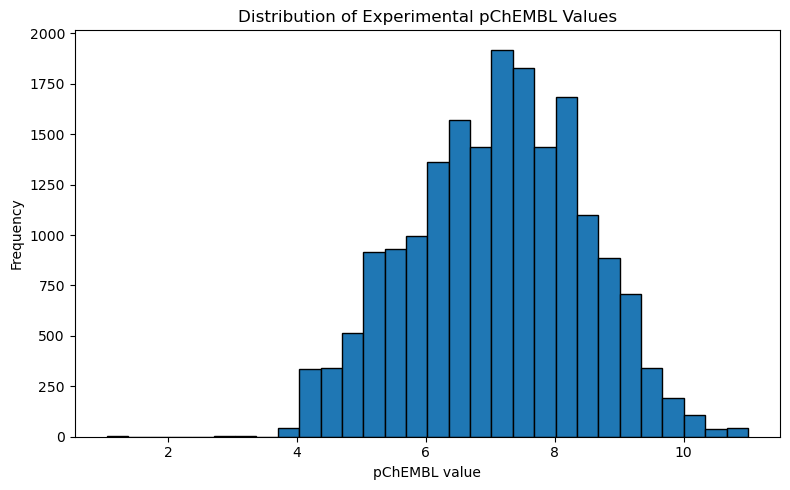

Saved: pchembl_distribution.png


In [71]:
plt.figure(figsize=(8, 5))

plt.hist(
    y,
    bins=30,
    edgecolor="black"
)

plt.xlabel("pChEMBL value")
plt.ylabel("Frequency")
plt.title("Distribution of Experimental pChEMBL Values")

plt.tight_layout()

plt.savefig(
    "../results/figures/pchembl_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: pchembl_distribution.png")

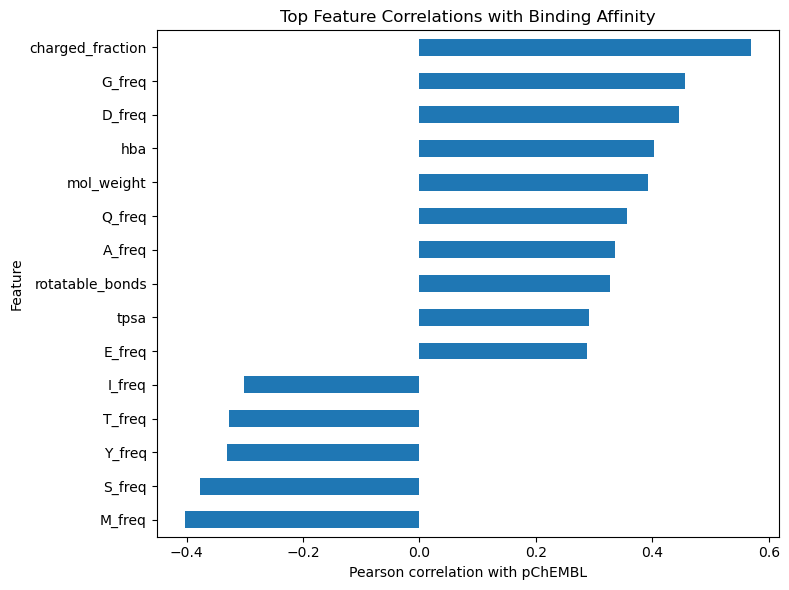

Saved: feature_correlation.png


In [72]:
plt.figure(figsize=(8, 6))

top_corr = correlations.head(15).sort_values()

top_corr.plot(kind="barh")

plt.xlabel("Pearson correlation with pChEMBL")
plt.ylabel("Feature")
plt.title("Top Feature Correlations with Binding Affinity")

plt.tight_layout()

plt.savefig(
    "../results/figures/feature_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: feature_correlation.png")

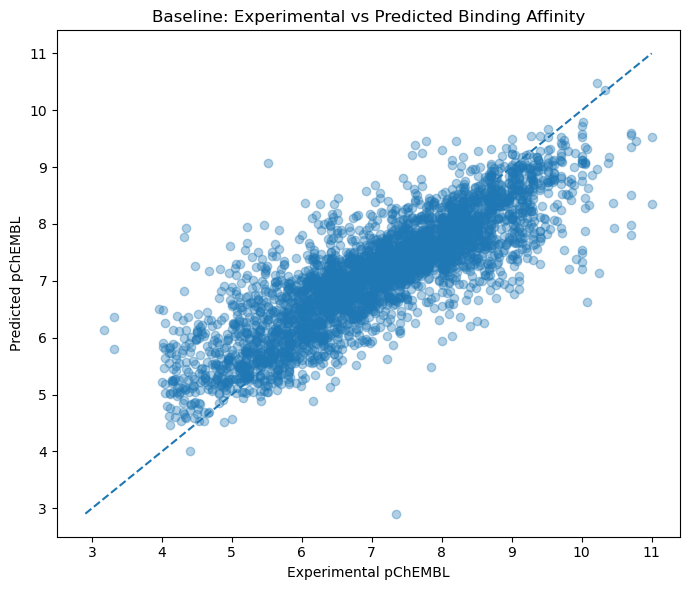

Saved: baseline_actual_vs_predicted.png


In [73]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.35
)

line_min = min(
    y_test.min(),
    y_pred.min()
)

line_max = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [line_min, line_max],
    [line_min, line_max],
    linestyle="--"
)

plt.xlabel("Experimental pChEMBL")
plt.ylabel("Predicted pChEMBL")
plt.title("Baseline: Experimental vs Predicted Binding Affinity")

plt.tight_layout()

plt.savefig(
    "../results/figures/baseline_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: baseline_actual_vs_predicted.png")

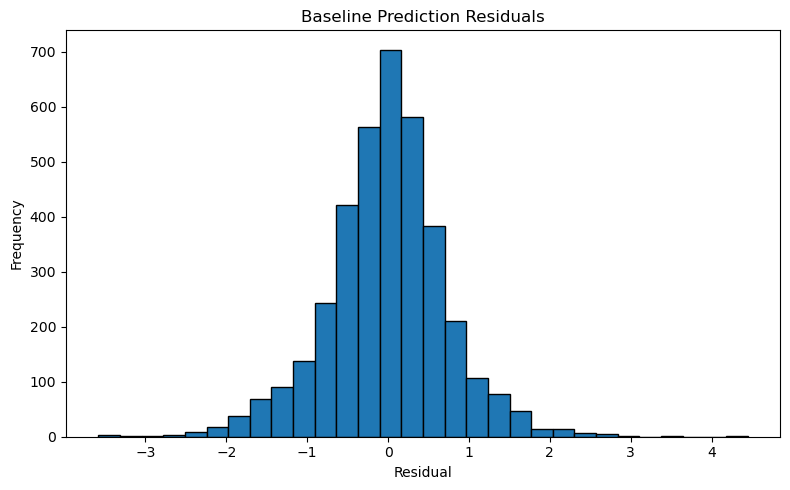

Saved: baseline_residuals.png


In [74]:
baseline_residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.hist(
    baseline_residuals,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Baseline Prediction Residuals")

plt.tight_layout()

plt.savefig(
    "../results/figures/baseline_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: baseline_residuals.png")

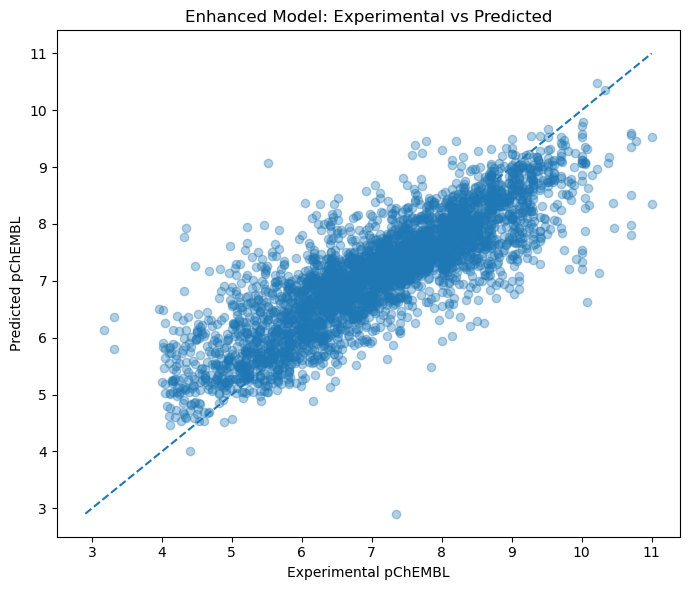

Saved: enhanced_actual_vs_predicted.png


In [75]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.35
)

line_min = min(
    y_test.min(),
    y_pred.min()
)

line_max = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [line_min, line_max],
    [line_min, line_max],
    linestyle="--"
)

plt.xlabel("Experimental pChEMBL")
plt.ylabel("Predicted pChEMBL")
plt.title("Enhanced Model: Experimental vs Predicted")

plt.tight_layout()

plt.savefig(
    "../results/figures/enhanced_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: enhanced_actual_vs_predicted.png")

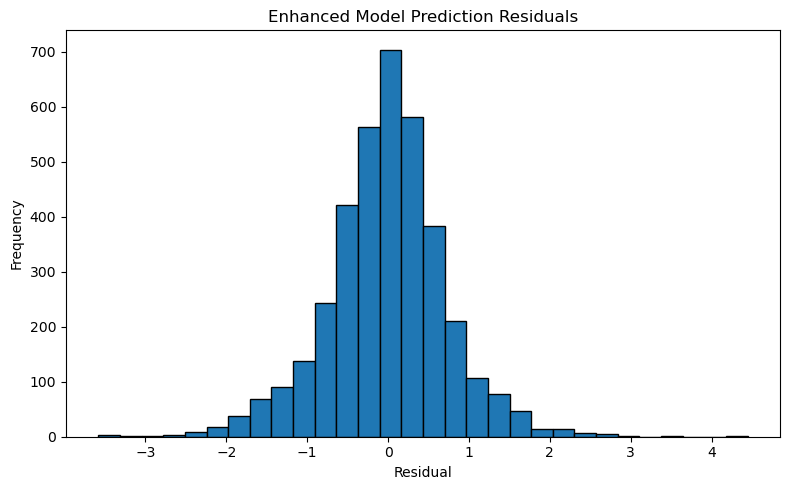

Saved: enhanced_residuals.png


In [76]:
enhanced_residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.hist(
    enhanced_residuals,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Enhanced Model Prediction Residuals")

plt.tight_layout()

plt.savefig(
    "../results/figures/enhanced_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: enhanced_residuals.png")

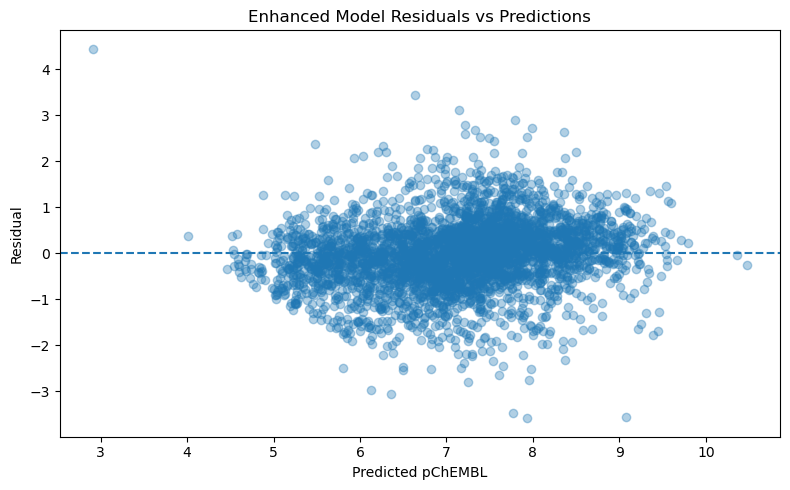

Saved: enhanced_residuals_vs_predictions.png


In [77]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred,
    enhanced_residuals,
    alpha=0.35
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted pChEMBL")
plt.ylabel("Residual")
plt.title("Enhanced Model Residuals vs Predictions")

plt.tight_layout()

plt.savefig(
    "../results/figures/enhanced_residuals_vs_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: enhanced_residuals_vs_predictions.png")

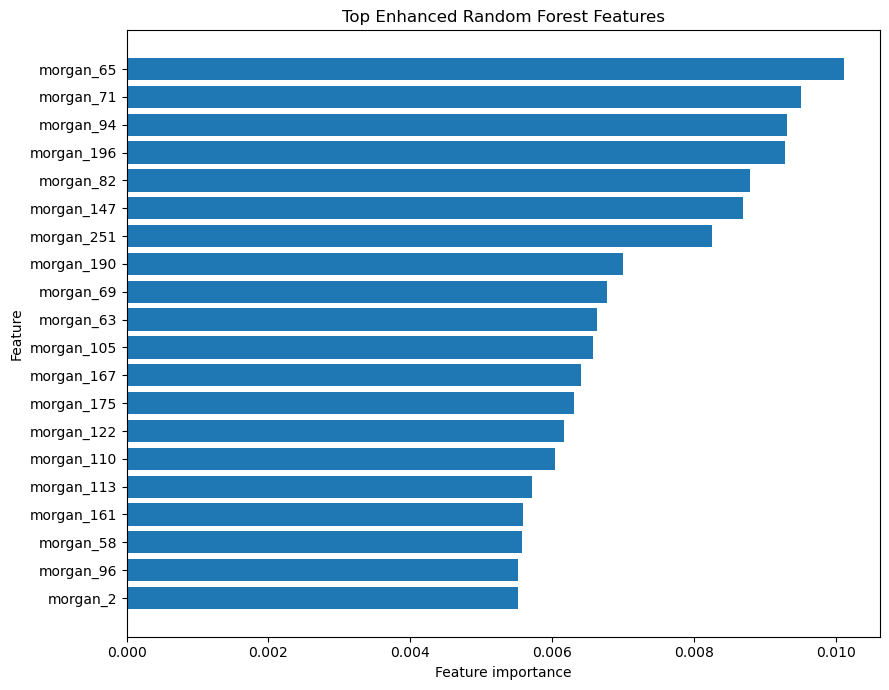

Saved: enhanced_feature_importance.png


In [78]:
top_importance = (
    importance_df
    .head(20)
    .sort_values("importance")
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_importance["feature"],
    top_importance["importance"]
)

plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Top Enhanced Random Forest Features")

plt.tight_layout()

plt.savefig(
    "../results/figures/enhanced_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: enhanced_feature_importance.png")

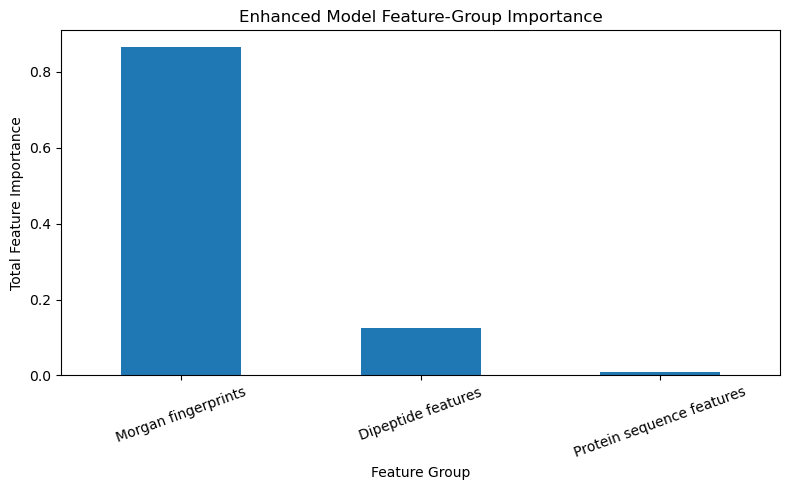

Saved: feature_group_importance.png


In [79]:
plt.figure(figsize=(8, 5))

group_importance.plot(
    kind="bar"
)

plt.ylabel("Total Feature Importance")
plt.xlabel("Feature Group")
plt.title("Enhanced Model Feature-Group Importance")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    "../results/figures/feature_group_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: feature_group_importance.png")

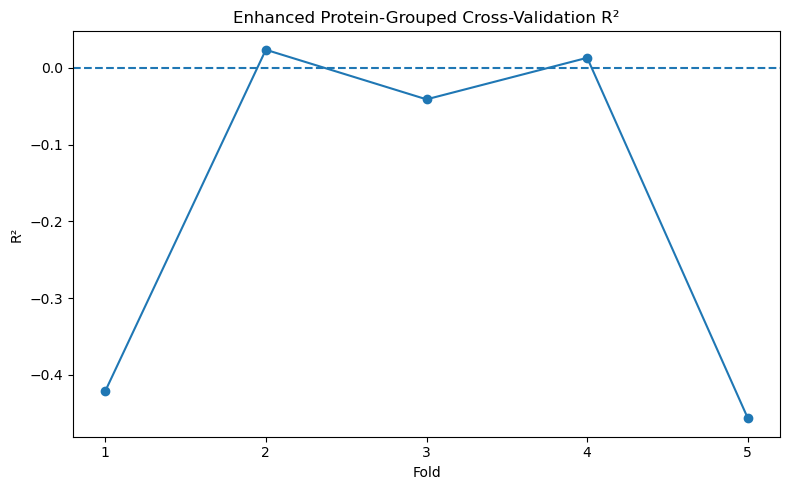

Saved: protein_grouped_cv.png


In [80]:
plt.figure(figsize=(8, 5))

plt.plot(
    cv_results_df["fold"],
    cv_results_df["R2"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Fold")
plt.ylabel("R²")
plt.title("Enhanced Protein-Grouped Cross-Validation R²")

plt.xticks(
    cv_results_df["fold"]
)

plt.tight_layout()

plt.savefig(
    "../results/figures/protein_grouped_cv.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: protein_grouped_cv.png")

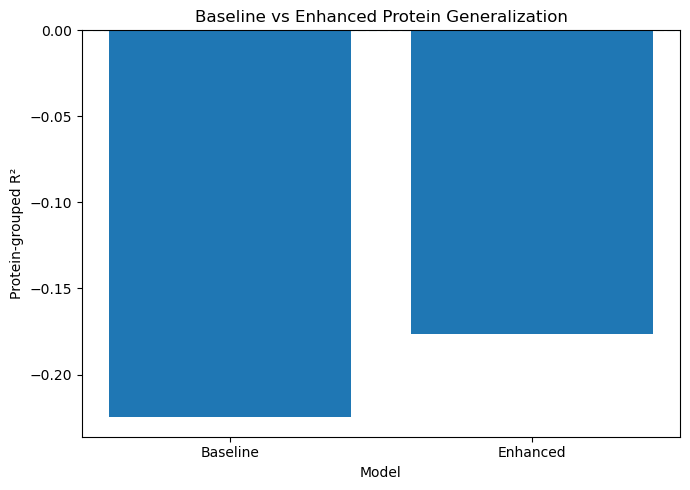

Saved: baseline_vs_enhanced.png


In [81]:
plt.figure(figsize=(7, 5))

plt.bar(
    final_comparison["Model"],
    final_comparison["Protein_Grouped_R2"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.ylabel("Protein-grouped R²")
plt.xlabel("Model")
plt.title("Baseline vs Enhanced Protein Generalization")

plt.tight_layout()

plt.savefig(
    "../results/figures/baseline_vs_enhanced.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: baseline_vs_enhanced.png")